# Milestone 2 🚩

In [1]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import librosa
import librosa.display
import matplotlib.pyplot as plt
import random
import soundfile as sf
import torch

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import warnings

warnings.filterwarnings("ignore")

## PART 1

In [2]:
DATA_ROOT = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]
STEMS = ['drums', 'vocals', 'bass', 'other']

In [3]:
data = []

for genre in GENRES:
    genre_path = os.path.join(DATA_ROOT, genre)
    songs = sorted(os.listdir(genre_path))
    for song_name in songs:
        for stem in STEMS:
            audio_path = os.path.join(genre_path, song_name, stem + ".wav")
            with sf.SoundFile(audio_path) as f:
                sr = f.samplerate
                duration = len(f) / sr
            data.append({
                "genre":genre,
                "song":song_name,
                "stem":stem,
                "path":audio_path,
                "file_size": os.path.getsize(audio_path),
                "sr":sr,
                "duration":duration
            })

In [4]:
df = pd.DataFrame(data)
df.head()

,genre,song,stem,path,file_size,sr,duration
0,blues,blues.00000,drums,/kaggle/input/jan-2026-dl-gen-ai-project/messy...,5294430,44100,30.013333
1,blues,blues.00000,vocals,/kaggle/input/jan-2026-dl-gen-ai-project/messy...,5294430,44100,30.013333
2,blues,blues.00000,bass,/kaggle/input/jan-2026-dl-gen-ai-project/messy...,5294430,44100,30.013333
3,blues,blues.00000,other,/kaggle/input/jan-2026-dl-gen-ai-project/messy...,5294430,44100,30.013333
4,blues,blues.00001,drums,/kaggle/input/jan-2026-dl-gen-ai-project/messy...,5294430,44100,30.013333


**Q1.** What is the mean duration (in seconds) of the Jazz genre stems in train dataset?

In [5]:
df[df["genre"]=="jazz"]["duration"].mean()

np.float64(30.032979591836728)

**Q2.** What are the unique sample rates present in the dataset? Enter your answer as a comma separated list. Example: [40000, 50000, 60000]

In [6]:
df["sr"].unique()

array([44100])

**Q3.** How many corrupted or zero-byte audio files are present in the train dataset?


In [7]:
(df["file_size"]==0).sum()

np.int64(0)

**Q4.** What is the average peak amplitude (in dB) for vocal stems in train dataset? 


In [8]:
def get_information(audio_path):
    y, sr = librosa.load(audio_path, sr=None)
    return y

df["audio_data"] = df["path"].apply(get_information)

In [9]:
df["peak_amplitude"] = df["audio_data"].map(lambda y : np.max(np.abs(y)))
df["peak_amplitude_dB"] = df["peak_amplitude"].map(lambda amp : librosa.amplitude_to_db(amp, ref=1.0))

In [10]:
df[df["stem"]=="vocals"]["peak_amplitude_dB"].mean()

np.float64(-12.494920925402944)

**Q5.** What is the mean spectral centroid for 'blues' genre in the train dataset?

In [11]:
def mean_spectal_centroid(y):
    centroids = librosa.feature.spectral_centroid(y=y, sr=44100)
    return centroids.mean()

df["spectal_centroid_means"] = df["audio_data"].map(mean_spectal_centroid)

In [12]:
df[df["genre"]=="blues"]["spectal_centroid_means"].mean()

np.float64(2296.7827371150856)

**Q6.** Which genre in the train dataset has the highest mean spectral centroid?

In [13]:
avg_df = (
    df
    .groupby("genre", as_index=False)["spectal_centroid_means"]
    .mean()
    .rename(columns={"spectal_centroid_means": "avg_spectal_centroid_means"})
    .sort_values("avg_spectal_centroid_means", ascending=False)
)
avg_df

,genre,avg_spectal_centroid_means
6,metal,2579.324315
5,jazz,2544.114957
3,disco,2454.153385
7,pop,2440.884881
8,reggae,2404.568993
4,hiphop,2370.789957
0,blues,2296.782737
2,country,2266.721002
9,rock,2250.084333
1,classical,1674.790326


**Q7.** How many stem audio files in the train dataset contain silence in the first 0.5 seconds?  

In [14]:
def first_half_second_silent(y):
    segment = y[:int(0.5 * 44100)] # get the samples belonging to first 0.5 second of the audio file
    non_silent = librosa.effects.split(segment, top_db=30) #split into segments
    return True if len(non_silent) == 0 else False

df["first_half_second_is_silent"] = df["audio_data"].map(first_half_second_silent)

In [15]:
df["first_half_second_is_silent"].sum()

np.int64(0)

In [16]:
# CLEAN UP

del df

## PART 2

In [17]:
# --- 1. Setup and Preprocessing ---
ROOT = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]

def extract_features(song_path):
    # Load 10s at 22050Hz
    y, sr = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050, duration=10)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
    return [float(tempo), spec_cent, zcr, rolloff]

# --- 2. Data Preparation & Stratified Split ---
data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = [s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))]
    for s in songs[:50]: # Sampling 50 for speed; use all for final
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['genre'], random_state=42)

# --- 3. Model Training (Decision Tree) ---
X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre']
X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre']

clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)
macro_f1 = f1_score(y_val, y_pred, average="macro")
cm = confusion_matrix(y_val, y_pred)
cr = classification_report(y_val, y_pred,zero_division=0.0)

print(f"Validation Macro F1 Score: {macro_f1:.4f}\n")
print("Detailed Classification Report:")
print(cr)

Validation Macro F1 Score: 0.1523

Detailed Classification Report:
              precision    recall  f1-score   support

       blues       0.20      0.10      0.13        10
   classical       0.14      0.10      0.12        10
     country       0.10      0.10      0.10        10
       disco       0.20      0.40      0.27        10
      hiphop       0.25      0.10      0.14        10
        jazz       0.00      0.00      0.00        10
       metal       0.41      0.90      0.56        10
         pop       0.20      0.20      0.20        10
      reggae       0.00      0.00      0.00        10
        rock       0.00      0.00      0.00        10

    accuracy                           0.19       100
   macro avg       0.15      0.19      0.15       100
weighted avg       0.15      0.19      0.15       100



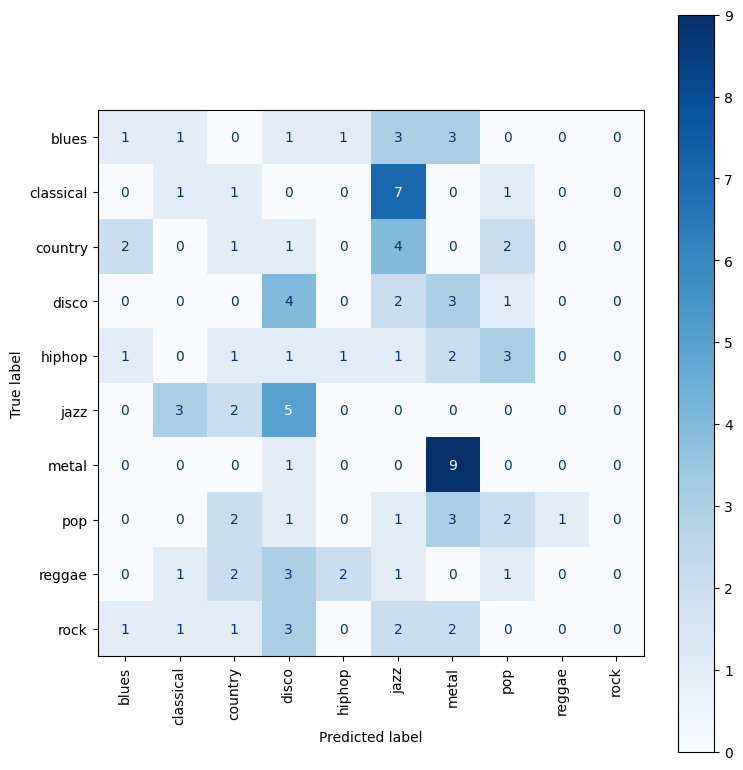

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot(cmap="Blues", ax=ax)

plt.setp(ax.get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

In [19]:
cm = confusion_matrix(y_val, y_pred, labels=clf.classes_)

# Calculate values
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
TN = cm.sum() - (TP + FP + FN)

# Build DataFrame
metrics_df = pd.DataFrame({
    "Label": clf.classes_,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "TN": TN
})

metrics_df

,Label,TP,FP,FN,TN
0,blues,1,4,9,86
1,classical,1,6,9,84
2,country,1,9,9,81
3,disco,4,16,6,74
4,hiphop,1,3,9,87
5,jazz,0,21,10,69
6,metal,9,13,1,77
7,pop,2,8,8,82
8,reggae,0,1,10,89
9,rock,0,0,10,90
